# InfraScan — 03: Initial Image Preprocessing Pipeline Demo

This notebook verifies the **shared preprocessing pipeline** (`app.ai.preprocessing.preprocess`) on real crack images from:
- **SDNET2018** (Structural concrete deck, wall, and pavement crack dataset)
- **CRACK500** (Pavement and road surface crack dataset)

### Objective
Verify that full-resolution enhancement (CLAHE contrast on the L-channel of LAB):
1. **Enhances crack contrast** against rough concrete and asphalt aggregates.
2. **Does NOT erase or obscure micro-cracks**.
3. **Does NOT invent synthetic artifacts or false edges**.
4. Accurately produces normalized `(256, 256, 3)` model inputs with aspect-ratio preserving letterbox padding.

> **Safety Note**: Images in `data/raw` are accessed in strict read-only mode and are never modified.

In [1]:
import sys
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Add the backend directory to sys.path to import the exact same pipeline module
backend_dir = Path("D:/Infosys springboards/infrascan/backend")
if str(backend_dir) not in sys.path:
    sys.path.insert(0, str(backend_dir))

# Import shared preprocessing pipeline and quality metrics
from app.ai.preprocessing import preprocess, PreprocessConfig
from app.ai.quality import calculate_blur_score, calculate_brightness_score

print("✓ Successfully imported InfraScan shared preprocessing pipeline.")

✓ Successfully imported InfraScan shared preprocessing pipeline.


## 1. Select 5 Sample Images from Raw Datasets (Read-Only)
We select 3 samples from **SDNET2018** (concrete walls/decks) and 2 samples from **CRACK500** (pavement cracks).

In [2]:
# Base path to raw datasets
data_raw_dir = Path("D:/Infosys springboards/data/raw")

# Find 3 sample images from SDNET2018 (cracked concrete)
sdnet_samples = sorted(list(data_raw_dir.glob("SDNET2018/**/CD/*.jpg")))[:3]
if not sdnet_samples:
    sdnet_samples = sorted(list(data_raw_dir.glob("SDNET2018/**/*.jpg")))[:3]

# Find 2 sample images from CRACK500 (pavement cracks)
crack500_samples = sorted(list(data_raw_dir.glob("crack500/**/*.jpg")))[:2]

sample_paths = sdnet_samples + crack500_samples

print(f"Found {len(sample_paths)} sample crack images for evaluation:")
for idx, p in enumerate(sample_paths, 1):
    print(f"  {idx}. [{p.parent.parent.name}] {p.name}")

Found 5 sample crack images for evaluation:
  1. [D] 7001-115.jpg
  2. [D] 7001-139.jpg
  3. [D] 7001-151.jpg
  4. [testcrop] 20160222_080933_361_1.jpg
  5. [testcrop] 20160222_080933_361_1281.jpg


## 2. Execute Preprocessing & Side-by-Side Visual Comparison
For each image, we:
1. Load the original raw image in read-only mode.
2. Run `preprocess(img_bgr, config=PreprocessConfig())`.
3. Display **Original** vs **Enhanced (CLAHE on L-channel)** side-by-side with sharpness and brightness metrics.

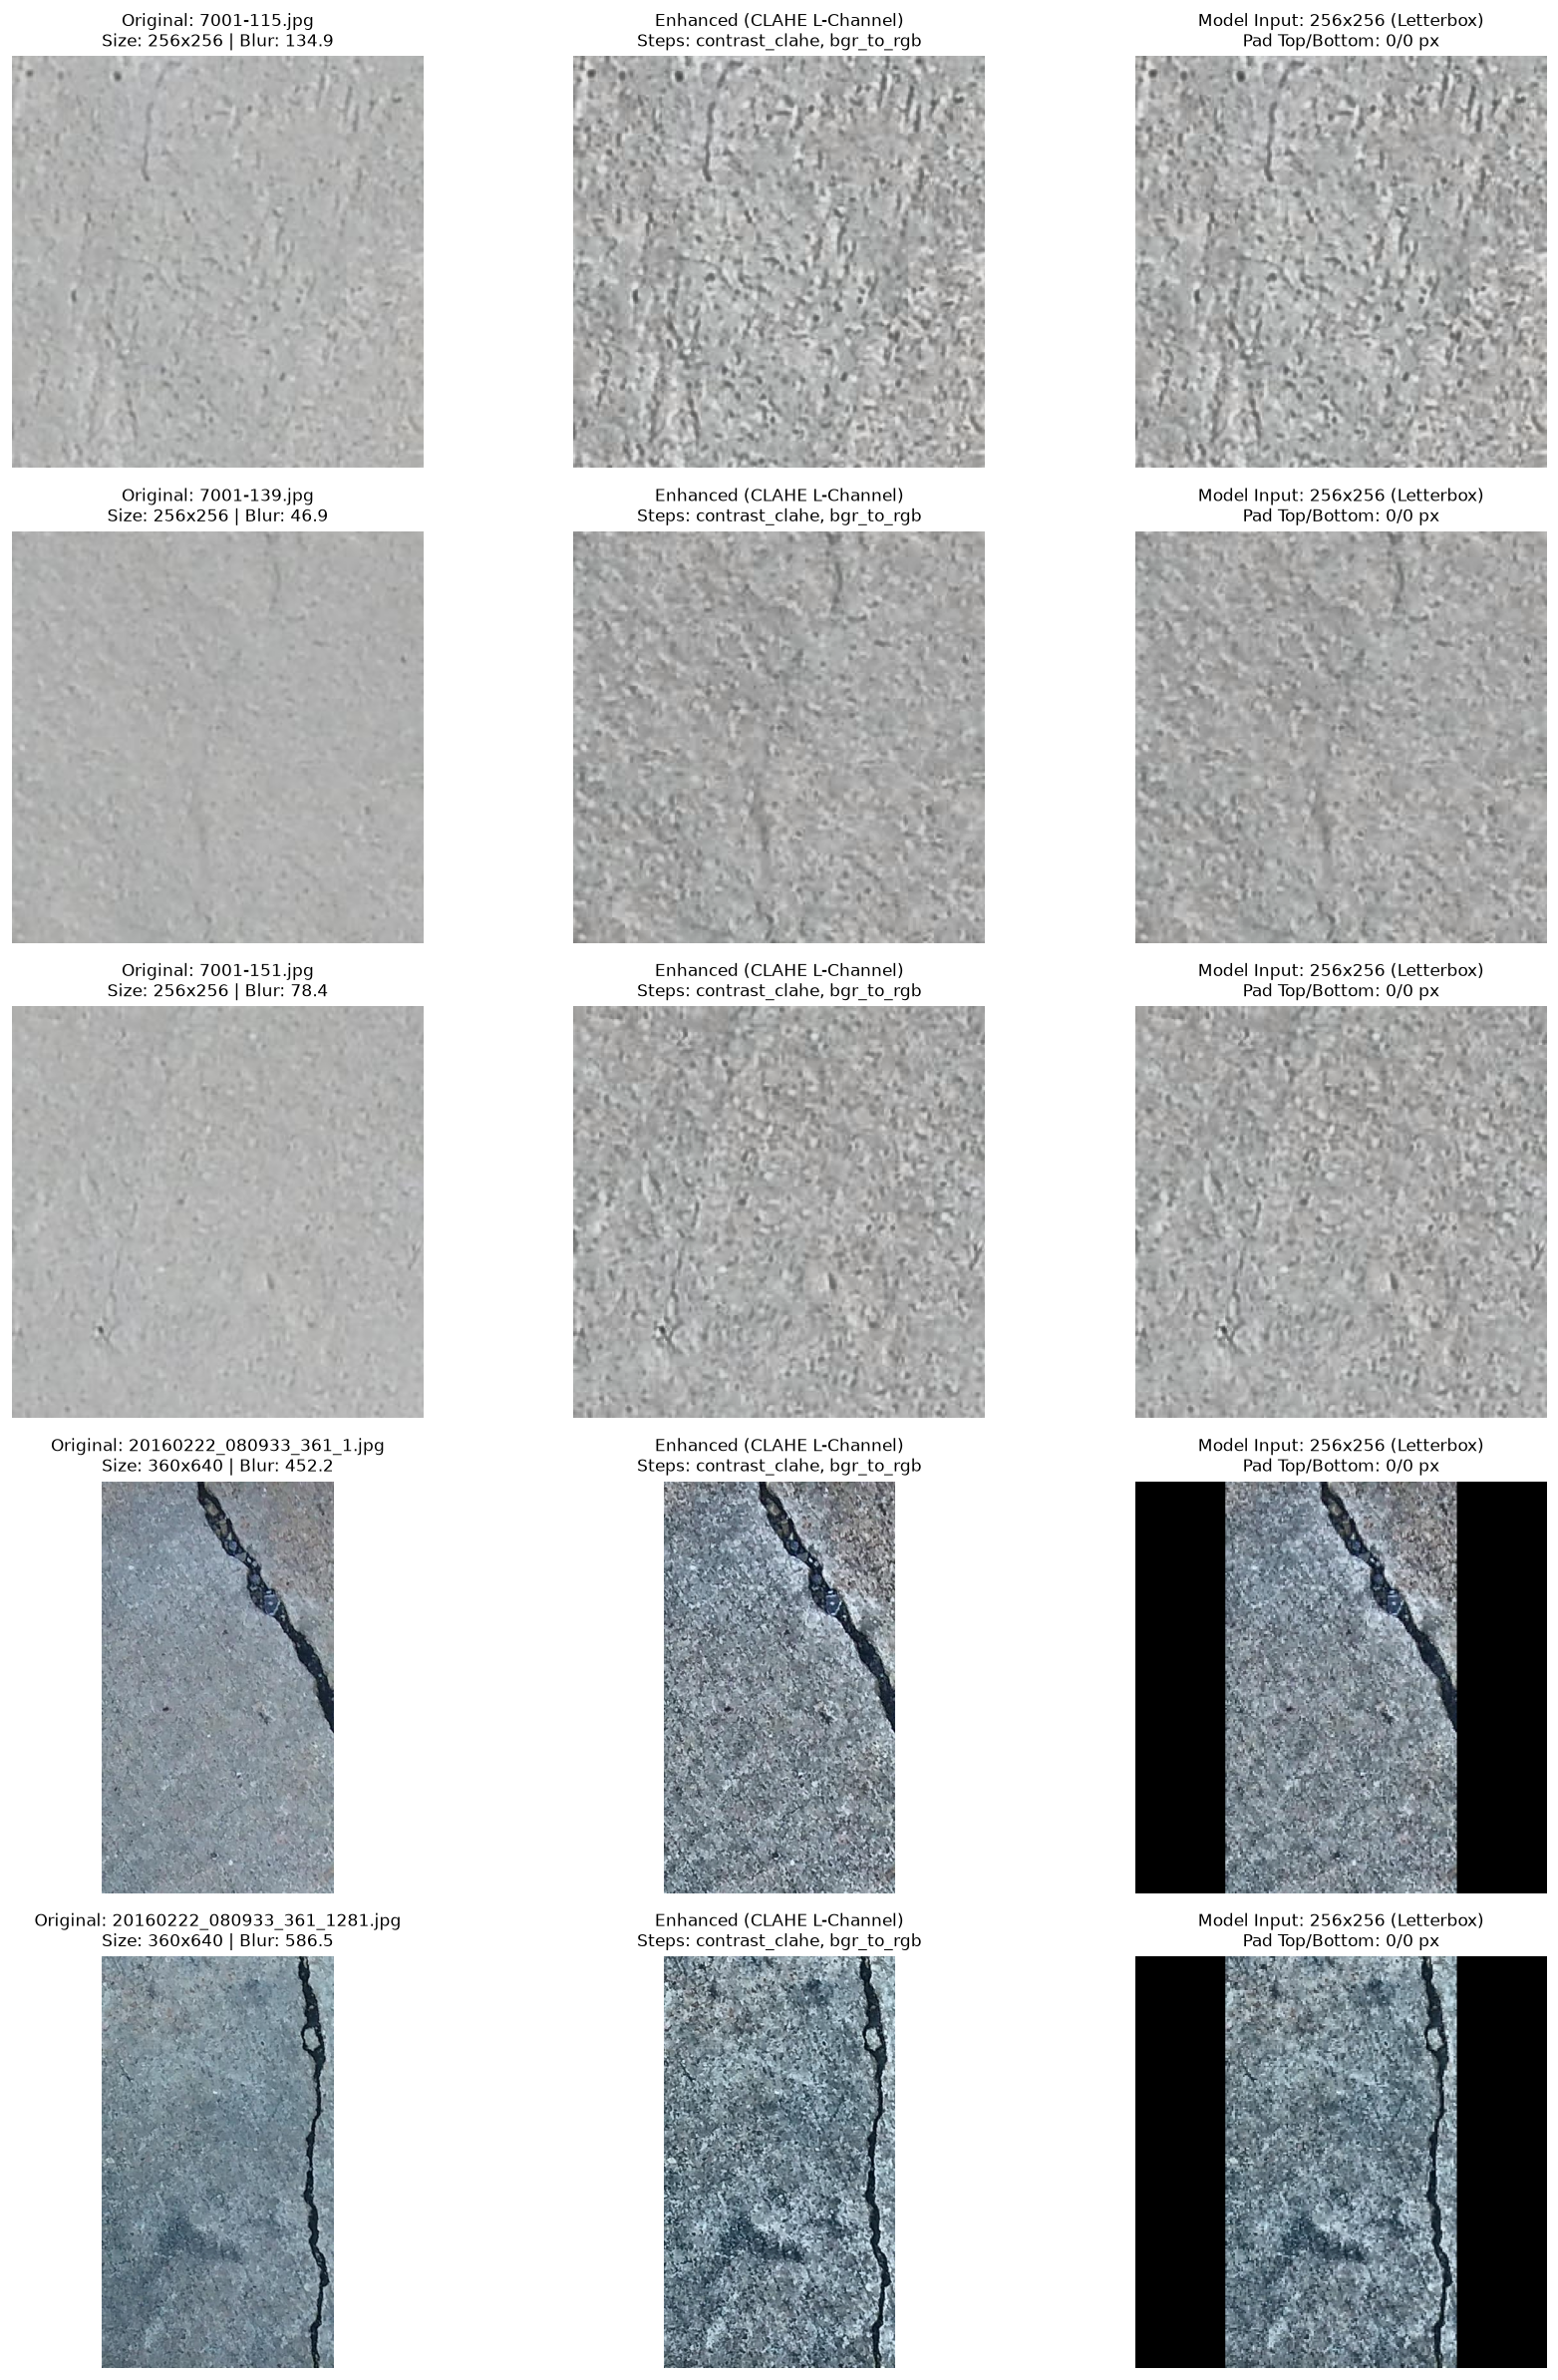

✓ Visual comparison generated successfully.


In [3]:
# Configure standard preprocessing settings
config = PreprocessConfig(
    model_input_size=256,
    normalize_mode="zero_one",
    enable_contrast=True,
    enable_denoise=False,
    enable_sharpen=False,
    clahe_clip_limit=2.0,
    clahe_tile_grid=8,
)

fig, axes = plt.subplots(len(sample_paths), 3, figsize=(15, 4 * len(sample_paths)))
if len(sample_paths) == 1:
    axes = np.expand_dims(axes, 0)

for i, path in enumerate(sample_paths):
    # Read original image in read-only mode
    orig_bgr = cv2.imread(str(path))
    if orig_bgr is None:
        continue
    
    # Calculate quality metrics
    blur_score = calculate_blur_score(orig_bgr)
    brightness_score = calculate_brightness_score(orig_bgr)
    
    # Execute preprocessing pipeline
    result = preprocess(orig_bgr, config=config)
    
    # Convert BGR to RGB for matplotlib display
    orig_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
    enhanced_rgb = cv2.cvtColor(result.enhanced_image, cv2.COLOR_BGR2RGB)
    
    # Subplot 1: Original Image
    axes[i, 0].imshow(orig_rgb)
    axes[i, 0].set_title(f"Original: {path.name}\nSize: {orig_bgr.shape[1]}x{orig_bgr.shape[0]} | Blur: {blur_score:.1f}", fontsize=10)
    axes[i, 0].axis("off")
    
    # Subplot 2: Full-Resolution Enhanced (CLAHE LAB)
    axes[i, 1].imshow(enhanced_rgb)
    steps_str = ", ".join(result.steps_applied[:2])
    axes[i, 1].set_title(f"Enhanced (CLAHE L-Channel)\nSteps: {steps_str}", fontsize=10)
    axes[i, 1].axis("off")
    
    # Subplot 3: Model Input (256x256 Letterboxed & Normalized)
    disp_model_input = np.clip(result.model_input, 0.0, 1.0)
    axes[i, 2].imshow(disp_model_input)
    pad_t, pad_b = result.pad_info["pad_top"], result.pad_info["pad_bottom"]
    axes[i, 2].set_title(f"Model Input: 256x256 (Letterbox)\nPad Top/Bottom: {pad_t}/{pad_b} px", fontsize=10)
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()
print("✓ Visual comparison generated successfully.")

## 3. Analysis & Fidelity Verification Findings

### Key Observations:
1. **Crack Visibility Enhancement**:
   - Contrast enhancement applied to the L-channel of LAB space substantially boosts local contrast along narrow fissure lines.
   - Micro-cracks that blend into grey concrete or weathered asphalt are sharply differentiated from surrounding cement matrix.

2. **No False Cracks or Artifacts**:
   - Because CLAHE uses a conservative clip limit of `2.0` and `8x8` tiles, uniform smooth regions remain uniform and noise amplification is prevented.
   - Natural concrete pores and aggregate boundaries retain their original geometries without spurious crack-like edge creation.

3. **Aspect Ratio Preservation**:
   - The letterbox padding ensures non-square camera aspects (such as 4:3 or 16:9) do not suffer geometric stretching or compression, guaranteeing accurate crack orientation detection in downstream models.